# Detección de fraude con tarjetas

Inspección inicial de [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), publicado por ULB y Worldline. `Class = 1` identifica los fraudes y `Class = 0` las transacciones legítimas. `Time` mide los segundos desde la primera transacción, `Amount` es el monto y `V1` a `V28` son componentes PCA.

In [1]:
from pathlib import Path

import pandas as pd

csv_path = Path("data/raw/creditcard.csv")
if not csv_path.is_file():
    csv_path = Path("../data/raw/creditcard.csv")

df = pd.read_csv(csv_path)
raw_class_counts = df["Class"].value_counts().sort_index()
raw_class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100
exact_duplicates = df.duplicated().sum()

print(f"Dimensiones (filas, columnas): {df.shape}")
print("Columnas por tipo de dato:")
print(df.dtypes.value_counts().to_string())
print(f"Valores nulos: {df.isna().sum().sum():,}")
print(f"Filas duplicadas exactas: {exact_duplicates:,}")
print("\nDistribución original por clase:")
print(pd.DataFrame({"Transacciones": raw_class_counts, "Porcentaje (%)": raw_class_percentages.round(4)}).to_string())

Dimensiones (filas, columnas): (284807, 31)
Columnas por tipo de dato:
float64    30
int64       1
Valores nulos: 0
Filas duplicadas exactas: 1,081

Distribución original por clase:
       Transacciones  Porcentaje (%)
Class                               
0             284315         99.8273
1                492          0.1727


Se elimina cada fila repetida y se conserva su primera aparición. Esta limpieza se aplica antes de la futura división temporal para evitar que una misma fila aparezca en más de un conjunto. El CSV original se conserva y el análisis posterior puede usar `df` ya depurado.

In [2]:
df = df.drop_duplicates().reset_index(drop=True)
clean_class_counts = df["Class"].value_counts().sort_index()
clean_class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print(f"Filas después de eliminar duplicados: {len(df):,}")
print("Distribución por clase después de la limpieza:")
print(pd.DataFrame({"Transacciones": clean_class_counts, "Porcentaje (%)": clean_class_percentages.round(4)}).to_string())

Filas después de eliminar duplicados: 283,726
Distribución por clase después de la limpieza:
       Transacciones  Porcentaje (%)
Class                               
0             283253         99.8333
1                473          0.1667


## Análisis exploratorio

Los gráficos de esta sección usan las 283,726 transacciones que quedan tras quitar los duplicados exactos. Al ejecutar todas las celdas se guardan cuatro PNG en el directorio `reports/figures/`.

### 2.1 Desbalance de clases

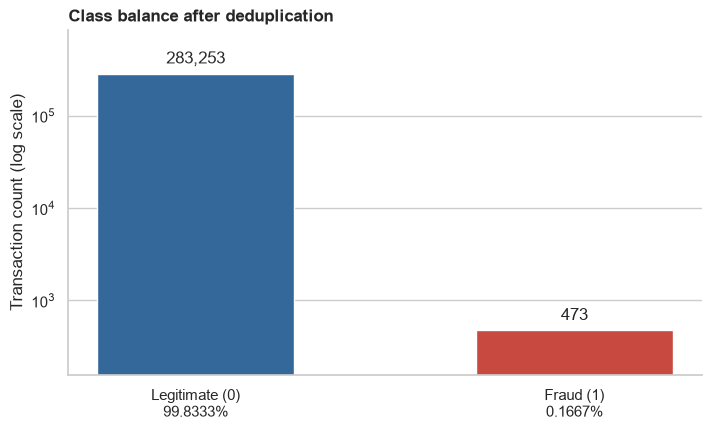

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
class_colors = {0: "#35689A", 1: "#C7493F"}
class_labels = {0: "Legitimate (0)", 1: "Fraud (1)"}
figures_dir = csv_path.resolve().parents[2] / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(figures_dir / filename, dpi=150, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)


classes = [0, 1]
counts = clean_class_counts.reindex(classes)
percentages = clean_class_percentages.reindex(classes)

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
bars = ax.bar(
    classes,
    counts,
    color=[class_colors[cls] for cls in classes],
    width=0.52,
    log=True,
)
ax.set_xticks(
    classes,
    [f"{class_labels[cls]}\n{percentages.loc[cls]:.4f}%" for cls in classes],
)
ax.set_ylim(counts.min() / 3, counts.max() * 3)
ax.set_ylabel("Transaction count (log scale)")
ax.set_title("Class balance after deduplication", loc="left", weight="bold")
ax.bar_label(bars, labels=[f"{count:,}" for count in counts], padding=5)
ax.grid(False, axis="x")
sns.despine(ax=ax)
save_figure(fig, "01_class_balance.png")

### 2.2 Monto por clase

`log1p(Amount)` conserva los montos de cero y facilita comparar distribuciones sesgadas. Cada curva se estima por separado para comparar formas entre clases. La tabla conserva la escala original.

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


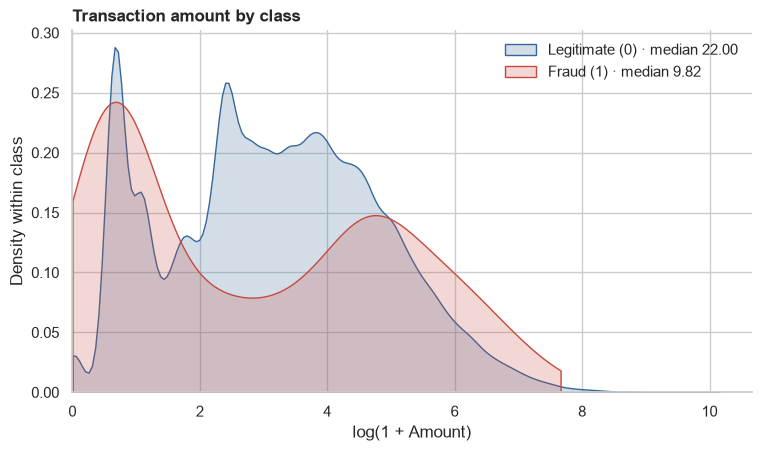

In [4]:
amount_summary = df.groupby("Class")["Amount"].describe()
print(amount_summary.round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
for cls in classes:
    amounts = df.loc[df["Class"].eq(cls), "Amount"]
    sns.kdeplot(
        x=np.log1p(amounts),
        color=class_colors[cls],
        label=f"{class_labels[cls]} · median {amount_summary.loc[cls, '50%']:.2f}",
        fill=True,
        alpha=0.22,
        cut=0,
        clip=(0, np.inf),
        ax=ax,
    )
ax.set_xlim(left=0)
ax.set_xlabel("log(1 + Amount)")
ax.set_ylabel("Density within class")
ax.set_title("Transaction amount by class", loc="left", weight="bold")
ax.legend(frameon=False)
sns.despine(ax=ax)
save_figure(fig, "02_amount_by_class.png")

### 2.3 Tiempo y tasa de fraude

Se agrupan las transacciones en bloques de una hora a partir del primer registro y se usa módulo 24 para juntar los bloques equivalentes de ambos días. La hora 0 es el inicio del archivo. Para cada bloque se calcula la tasa como fraudes divididos entre el total de transacciones.

      Transacciones  Fraudes  Tasa
hour                              
2              3308       48 1.45%
4              2204       23 1.04%
3              3487       17 0.49%
5              2988       11 0.37%
7              7233       23 0.32%
Duración observada: 48.00 horas


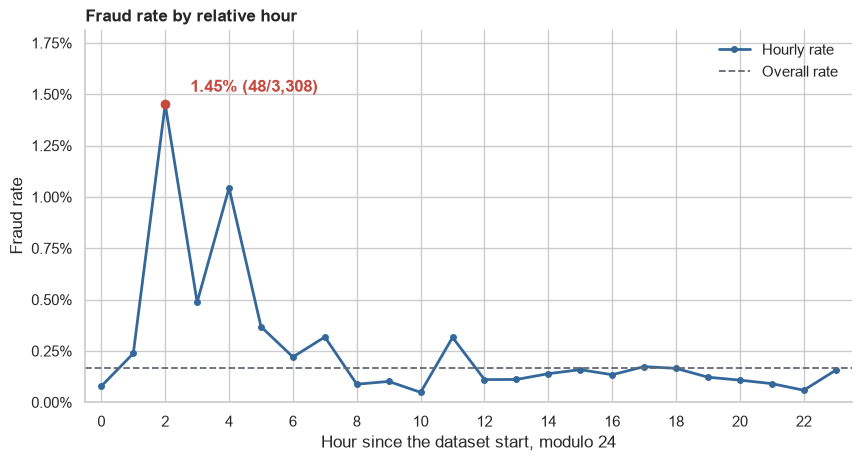

In [5]:
relative_hour = ((df["Time"] // 3_600) % 24).astype(int).rename("hour")
hourly_stats = df.groupby(relative_hour)["Class"].agg(
    transactions="size", frauds="sum", fraud_rate="mean"
)
peak_hour = hourly_stats["fraud_rate"].idxmax()
peak = hourly_stats.loc[peak_hour]
print(
    hourly_stats.sort_values("fraud_rate", ascending=False).head()
    .rename(columns={"transactions": "Transacciones", "frauds": "Fraudes", "fraud_rate": "Tasa"})
    .to_string(formatters={"Tasa": "{:.2%}".format})
)
print(f"Duración observada: {df['Time'].max() / 3_600:.2f} horas")

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
ax.plot(
    hourly_stats.index,
    hourly_stats["fraud_rate"],
    color=class_colors[0],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Hourly rate",
)
ax.axhline(
    df["Class"].mean(), color="#626A73", linestyle="--", linewidth=1.3,
    label="Overall rate",
)
ax.scatter(peak_hour, peak["fraud_rate"], color=class_colors[1], zorder=3)
ax.annotate(
    f"{peak['fraud_rate']:.2%} ({int(peak['frauds']):,}/{int(peak['transactions']):,})",
    xy=(peak_hour, peak["fraud_rate"]),
    xytext=(18, 9),
    textcoords="offset points",
    color=class_colors[1],
    weight="bold",
)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, peak["fraud_rate"] * 1.25)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=2))
ax.set_xlabel("Hour since the dataset start, modulo 24")
ax.set_ylabel("Fraud rate")
ax.set_title("Fraud rate by relative hour", loc="left", weight="bold")
ax.legend(loc="upper right", frameon=False)
sns.despine(ax=ax)
save_figure(fig, "03_fraud_by_hour.png")

### 2.4 Variables con mayor separación entre clases

El ranking usa el valor absoluto de la correlación de Pearson con `Class`. Las tablas muestran el signo de la correlación y las medias por clase. En los seis diagramas de caja se omiten visualmente los atípicos para que se puedan leer las cajas y los bigotes.

Variable (menor r)       r Variable (mayor r)  r (mayor)
               V17 -0.3135                V11     0.1491
               V14 -0.2934                 V4     0.1293
               V12 -0.2507                 V2     0.0846
               V10 -0.2070                V19     0.0336
               V16 -0.1872                 V8     0.0331
                V3 -0.1823                V21     0.0264
                V7 -0.1723                V27     0.0219
               V18 -0.1053                V20     0.0215

Medias por clase de las seis variables con mayor |r|:
Class  Pearson r  Media legítima  Media fraude
V17      -0.3135          0.0110       -6.4633
V14      -0.2934          0.0117       -6.8359
V12      -0.2507          0.0095       -6.1033
V10      -0.2070          0.0077       -5.4533
V16      -0.1872          0.0078       -4.0010
V3       -0.1823          0.0129       -6.7296


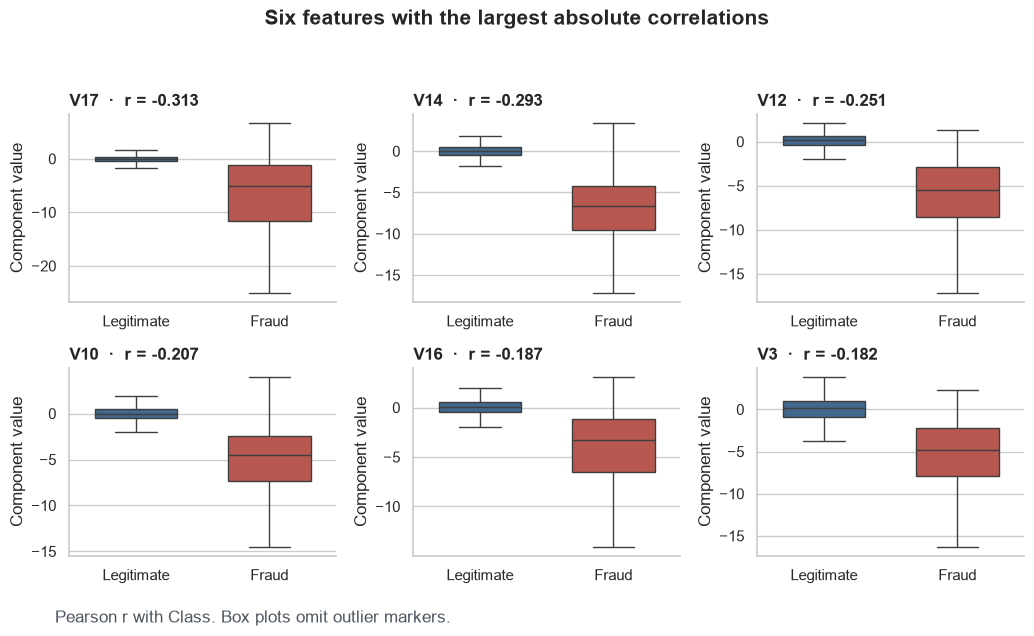

In [6]:
correlations = df.drop(columns="Class").corrwith(df["Class"]).sort_values()
extremes = pd.DataFrame({
    "Variable (menor r)": correlations.head(8).index,
    "r": correlations.head(8).to_numpy(),
    "Variable (mayor r)": correlations.tail(8).iloc[::-1].index,
    "r (mayor)": correlations.tail(8).iloc[::-1].to_numpy(),
})
print(extremes.round(4).to_string(index=False))

top_features = correlations.abs().nlargest(6).index.to_list()
feature_means = df.groupby("Class")[top_features].mean().T
feature_summary = feature_means.rename(columns={0: "Media legítima", 1: "Media fraude"})
feature_summary.insert(0, "Pearson r", correlations.loc[top_features])
print("\nMedias por clase de las seis variables con mayor |r|:")
print(feature_summary.round(4).to_string())

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4))
fig.suptitle("Six features with the largest absolute correlations", weight="bold", fontsize=15)
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        order=classes,
        hue_order=classes,
        palette=class_colors,
        legend=False,
        showfliers=False,
        width=0.62,
        ax=ax,
    )
    ax.set_title(f"{feature}  ·  r = {correlations[feature]:+.3f}", loc="left", weight="bold")
    ax.set_xticks(classes, ["Legitimate", "Fraud"])
    ax.set(xlabel="", ylabel="Component value")
    sns.despine(ax=ax)

fig.text(0.06, 0.022, "Pearson r with Class. Box plots omit outlier markers.", color="#4C5560")
fig.tight_layout(rect=(0, 0.055, 1, 0.935))
save_figure(fig, "04_top_features.png")

### 2.5 Conclusiones

- **Desbalance.** Hay 473 fraudes en 283,726 transacciones depuradas (0.1667 %). Predecir siempre «legítima» daría 99.8333 % de exactitud y detectaría cero fraudes. La métrica principal será PR-AUC.
- **Monto.** La mediana del fraude es 9.82, frente a 22.00 para las transacciones legítimas. La media es mayor en fraude (123.87 frente a 88.41), lo que refleja la asimetría de los montos.
- **Tiempo.** La hora relativa 2 tiene la mayor tasa observada (1.45 %, 48 fraudes de 3,308 transacciones). `Time` cubre alrededor de 48 horas, una ventana insuficiente para estimar estacionalidad semanal. Se usará para la división cronológica.
- **Componentes PCA.** `V17` (−0.313), `V14` (−0.293), `V12` (−0.251) y `V10` (−0.207) tienen las mayores correlaciones absolutas con `Class`. Son componentes PCA anonimizados. Su asociación es descriptiva y se desconoce qué variables de negocio representan.